# Online retail: customer segmentation with RFM

**Question:** Which customer groups deserve different retention, growth, or win-back actions?

Dataset: [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail). This notebook turns raw invoices into customer-level Recency, Frequency, and Monetary-value features before clustering.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

DATA_PATH = Path('../datasets/online-retail/Online Retail.csv')

raw = pd.read_csv(DATA_PATH, sep=';', decimal=',', parse_dates=['InvoiceDate'], dayfirst=True, encoding='latin1')
print(raw.shape)
display(raw.head())
display(raw.isna().sum().sort_values(ascending=False).to_frame('missing'))

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,missing
CustomerID,135080
Description,1454
StockCode,0
InvoiceNo,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


In [2]:
# Keep completed, priced product lines with an identifiable customer.
# Invoice numbers beginning with C represent cancellations/credit notes.
transactions = raw.dropna(subset=['CustomerID']).copy()
transactions = transactions[~transactions['InvoiceNo'].astype(str).str.startswith('C')]
transactions = transactions[(transactions['Quantity'] > 0) & (transactions['UnitPrice'] > 0)]
transactions['InvoiceDate'] = pd.to_datetime(transactions['InvoiceDate'])
transactions['revenue'] = transactions['Quantity'] * transactions['UnitPrice']
print(f'Clean transactions: {len(transactions):,}; customers: {transactions.CustomerID.nunique():,}')

Clean transactions: 397,884; customers: 4,338


In [3]:
# RFM converts transaction-level events into one row per customer.
# The snapshot is set one day after the final purchase to avoid zero-day recency.
snapshot_date = transactions['InvoiceDate'].max() + pd.Timedelta(days=1)
rfm = transactions.groupby('CustomerID').agg(
    recency_days=('InvoiceDate', lambda dates: (snapshot_date - dates.max()).days),
    frequency=('InvoiceNo', 'nunique'),
    monetary_value=('revenue', 'sum'),
).reset_index()
display(rfm.describe().T)

# RFM is heavily right-skewed; log transformation prevents a few large buyers dominating Euclidean distance.
rfm_features = ['recency_days', 'frequency', 'monetary_value']
X = np.log1p(rfm[rfm_features])
scaled = StandardScaler().fit_transform(X)

,count,mean,std,min,25%,50%,75%,max
CustomerID,4338.0,15300.408022,1721.808492,12346.00,13813.250,15299.500,16778.75,18287.00
recency_days,4338.0,92.536422,100.014169,1.00,18.000,51.000,142.00,374.00
frequency,4338.0,4.272015,7.697998,1.00,1.000,2.000,5.00,209.00
monetary_value,4338.0,2054.266460,8989.230441,3.75,307.415,674.485,1661.74,280206.02


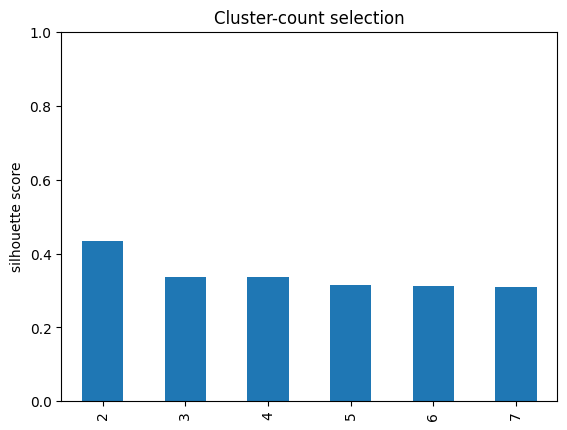

Selected clusters: 2


In [4]:
# Select k using silhouette score instead of choosing a convenient-looking number.
candidates = range(2, 8)
silhouettes = {}
for k in candidates:
    labels = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(scaled)
    silhouettes[k] = silhouette_score(scaled, labels)

best_k = max(silhouettes, key=silhouettes.get)
pd.Series(silhouettes, name='silhouette_score').plot(kind='bar', ylim=(0, 1), title='Cluster-count selection')
plt.ylabel('silhouette score'); plt.show()
print('Selected clusters:', best_k)

kmeans = KMeans(n_clusters=best_k, n_init=20, random_state=42)
rfm['segment'] = kmeans.fit_predict(scaled)

,customers,median_recency_days,median_frequency,median_monetary_value,total_revenue,revenue_share
segment,,,,,,
1,1667,16.0,6.0,2064.95,7581946.78,0.85
0,2671,96.0,1.0,363.88,1329461.12,0.15


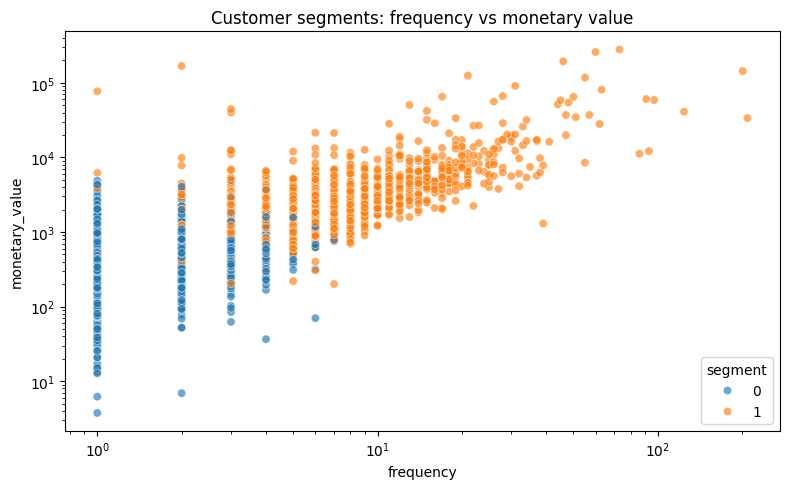

In [5]:
# Give the clusters a business-readable profile before assigning any marketing action.
profile = rfm.groupby('segment').agg(
    customers=('CustomerID', 'size'),
    median_recency_days=('recency_days', 'median'),
    median_frequency=('frequency', 'median'),
    median_monetary_value=('monetary_value', 'median'),
    total_revenue=('monetary_value', 'sum'),
).sort_values('total_revenue', ascending=False)
profile['revenue_share'] = profile['total_revenue'] / profile['total_revenue'].sum()
display(profile.round(2))

plt.figure(figsize=(8, 5))
sns.scatterplot(data=rfm, x='frequency', y='monetary_value', hue='segment', palette='tab10', alpha=0.65)
plt.xscale('log'); plt.yscale('log'); plt.title('Customer segments: frequency vs monetary value'); plt.tight_layout(); plt.show()

## Recommended actions and limitations

Name segments only after reviewing the profile—for example, frequent/high-value customers may receive VIP retention treatment, while formerly valuable but high-recency customers are win-back candidates. Clusters are descriptive, not causal. Next, validate actions with controlled experiments, re-run the segmentation regularly, and include margin and acquisition-channel data.